# Public benchmark, UCI Airfoil Self-Noise: Fig. 6

Five models trained once on 500 points; the remaining 1003 points are split $10^5$ times at random into $N_\mathrm{cal}=100$ calibration and 903 test points. The indices come from the package. Data: Brooks, Pope and Marcolini (1989), UCI Machine Learning Repository, doi:10.24432/C5VW2C, CC BY 4.0. Runs in about a minute.

In [1]:
import hashlib
import sys
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.lines import Line2D
from matplotlib.ticker import NullFormatter
from sklearn.compose import TransformedTargetRegressor
from sklearn.ensemble import GradientBoostingRegressor, RandomForestRegressor
from sklearn.exceptions import ConvergenceWarning
from sklearn.linear_model import LinearRegression
from sklearn.neural_network import MLPRegressor
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import PolynomialFeatures, StandardScaler

import reliable_conformal_prediction as rcp

HERE = Path.cwd()
sys.path.insert(0, str(HERE))
import cp_plot as cpl  # noqa: E402
import cp_tools as ct  # noqa: E402

FIG = HERE / "figures"
DATA = HERE / "data" / "airfoil" / "airfoil_self_noise.dat"
assert hashlib.sha256(DATA.read_bytes()).hexdigest() == "74c75fd71783f1e6b71f8a622b993dc592897a97cd689c5090a07147a1b097b3"

In [2]:
COLS = ["frequency (Hz)", "angle of attack (deg)", "chord length (m)", "free-stream velocity (m/s)",
        "suction-side displacement thickness (m)", "scaled sound pressure level (dB)"]
df = pd.DataFrame(np.loadtxt(DATA), columns=COLS)
X, y = df[COLS[:5]].to_numpy(), df[COLS[5]].to_numpy()

C_NOM = C_MIN = 0.9
CONF = 0.95
N_TRAIN = 500
rng = np.random.default_rng(ct.seed_for("D1 airfoil training set"))
perm = rng.permutation(len(y))
tr, pool_idx = perm[:N_TRAIN], perm[N_TRAIN:]

MODELS = {  # hyperparameters fixed in advance
    "linear regression": LinearRegression(),
    "polynomial, degree 4": make_pipeline(StandardScaler(), PolynomialFeatures(4), LinearRegression()),
    "random forest": RandomForestRegressor(n_estimators=500, random_state=1),
    "gradient boosting": GradientBoostingRegressor(n_estimators=500, learning_rate=0.05, max_depth=4, subsample=0.8,
                                                   random_state=1),
    "MLP": TransformedTargetRegressor(make_pipeline(StandardScaler(), MLPRegressor(hidden_layer_sizes=(64, 64), max_iter=5000,
                                                                                   random_state=1)),
                                      transformer=StandardScaler())}
scores = {}
for name, model in MODELS.items():
    with warnings.catch_warnings():
        warnings.simplefilter("ignore", ConvergenceWarning)
        model.fit(X[tr], y[tr])
    scores[name] = np.abs(y[pool_idx] - model.predict(X[pool_idx]))  # absolute error (dB) on the pool

In [3]:
R = 100_000
N8 = 100
T8 = pool_idx.size - N8


def run_splits(name, N, key):
    T = pool_idx.size - N
    ms = {"standard": rcp.get_index_standard(N, C_NOM), "new": rcp.get_index(N, C_MIN, CONF)}  # 91 and 96
    sim = ct.simulate_splits(scores[name], N, ms, R, key)
    out = []
    for proc, m in ms.items():
        frac, lo, hi = ct.frac_below(sim["count"][proc] / T, C_MIN)
        q05, q50, q95 = np.quantile(sim["thr"][proc], (0.05, 0.5, 0.95))
        out.append({"model": name, "procedure": proc, "P(observed < 0.9): splits": frac, "99% CI low": lo,
                    "99% CI high": hi,
                    "P(observed < 0.9): beta-binomial": ct.test_count_law(T, N, m).cdf(int(np.ceil(C_MIN * T)) - 1),
                    "half-width p05 (dB)": q05, "median half-width (dB)": q50, "half-width p95 (dB)": q95})
    return out


T14 = pd.DataFrame([r for name in MODELS for r in run_splits(name, N8, f"D2 airfoil splits {name} {N8}")])

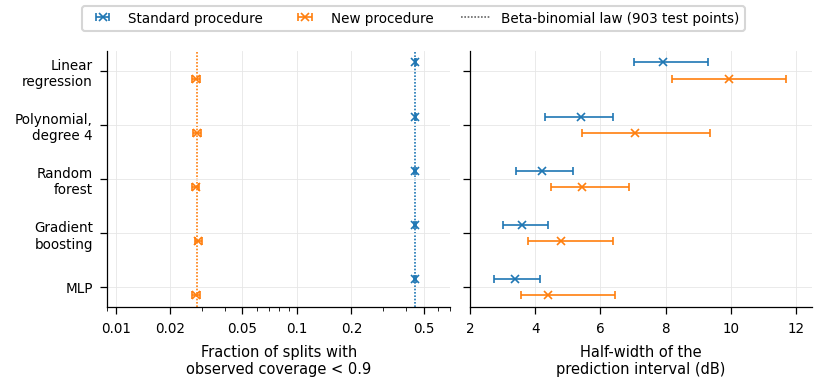

In [4]:
NAME8 = {"linear regression": "Linear\nregression", "polynomial, degree 4": "Polynomial,\ndegree 4",
         "random forest": "Random\nforest", "gradient boosting": "Gradient\nboosting", "MLP": "MLP"}
labels8 = list(MODELS)
yy = np.arange(len(labels8))
EB = dict(fmt="x", ms=4, mew=0.8, lw=0.8, capsize=2, capthick=0.8)
XTICKS_A = [0.01, 0.02, 0.05, 0.1, 0.2, 0.5]
with cpl.style():
    fig, (a1, a2) = plt.subplots(1, 2, figsize=(cpl.TEXT_WIDTH, 2.5), sharey=True, layout="constrained")
    handles = []
    for k, off, proc in (("std", -0.15, "standard"), ("new", 0.15, "new")):
        d = T14[T14.procedure == proc].set_index("model").loc[labels8]
        # left: fraction of splits whose observed coverage is below 0.9 (bars: 99% Monte Carlo interval)
        p = d["P(observed < 0.9): splits"]
        a1.errorbar(p, yy + off, xerr=[p - d["99% CI low"], d["99% CI high"] - p], color=cpl.COL[k], **EB)
        a1.axvline(d["P(observed < 0.9): beta-binomial"].iloc[0], color=cpl.COL[k], lw=0.8, ls=(0, (1, 1)), zorder=0)
        # right: half-width over the splits (median, bars 5-95%)
        h = d["median half-width (dB)"]
        handles.append(a2.errorbar(h, yy + off, xerr=[h - d["half-width p05 (dB)"], d["half-width p95 (dB)"] - h],
                                   color=cpl.COL[k], **EB))
    a1.set_xscale("log")
    a1.set_xticks(XTICKS_A, [f"{t:g}" for t in XTICKS_A])
    a1.xaxis.set_minor_formatter(NullFormatter())
    a1.set(xlim=(0.009, 0.7), xlabel="Fraction of splits with\nobserved coverage < 0.9")
    a2.set(xlim=(2, 12.5), xlabel="Half-width of the\nprediction interval (dB)")
    a1.set_yticks(yy, [NAME8[m] for m in labels8])
    a1.invert_yaxis()
    fig.legend(handles + [Line2D([], [], color="0.4", ls=(0, (1, 1)), lw=0.8)],
               [cpl.LABEL["std"], cpl.LABEL["new"], f"Beta-binomial law ({T8} test points)"],
               loc="outside upper center", ncol=3)
    cpl.savefig(fig, "fig_public_models", figdir=FIG)
    plt.show()